# FunctionTransform & StatefulFunctionTransform

Interactive tests for `FunctionTransform` (stateless) and `StatefulFunctionTransform` (stateful) in the `tensorts` library.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import medfilt

from tensorts import (
    TimeTensor, Dim, ChannelIndex,
    FunctionTransform, StatefulFunctionTransform, Scope,
    StandardScaler, SlidingWindow, Flatten,
    ChannelSelect, Pipeline,
    make_statistical_extractor, temporal_split,
)

np.random.seed(42)

---
## 1. FunctionTransform -- PER_CHANNEL

### 1a. Median filter (dense)

In [2]:
# Create a noisy 3-channel signal
data = np.random.randn(5, 100, 3).astype(np.float64)
ts = TimeTensor(data, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL),
                channels=["acc_x", "acc_y", "acc_z"])

smooth = FunctionTransform(fn=medfilt, scope=Scope.PER_CHANNEL,
                           fn_kwargs={"kernel_size": 3})
ts_smooth = smooth.fit_transform(ts)

print(f"Shape  before: {ts.shape}  -> after: {ts_smooth.shape}")
print(f"Dims   before: {ts.dims}   -> after: {ts_smooth.dims}")
print(f"Channels before: {ts.channels.names} -> after: {ts_smooth.channels.names}")

Shape  before: (5, 100, 3)  -> after: (5, 100, 3)
Dims   before: (Dim.BATCH, Dim.TIME, Dim.CHANNEL)   -> after: (Dim.BATCH, Dim.TIME, Dim.CHANNEL)
Channels before: ('acc_x', 'acc_y', 'acc_z') -> after: ('acc_x', 'acc_y', 'acc_z')


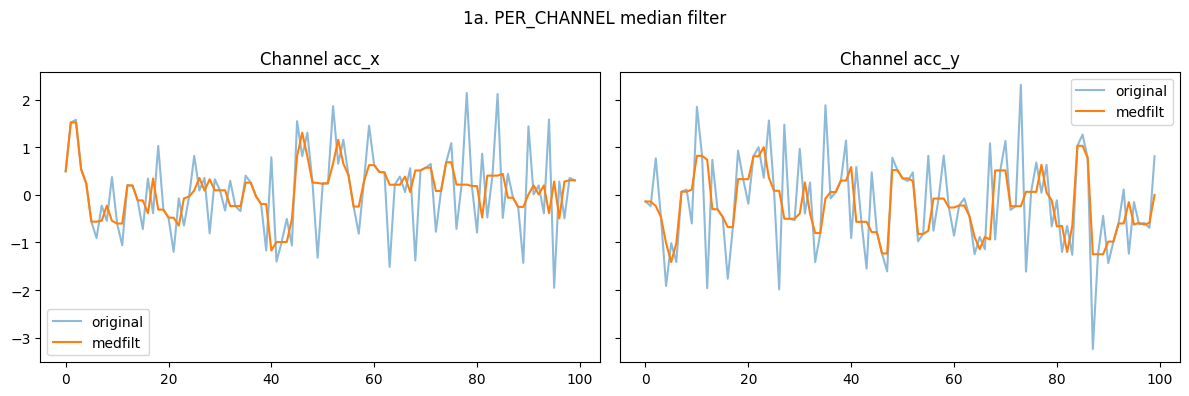

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for i, ch in enumerate([0, 1]):
    axes[i].plot(ts.data[0, :, ch], alpha=0.5, label="original")
    axes[i].plot(ts_smooth.data[0, :, ch], label="medfilt")
    axes[i].set_title(f"Channel {ts.channels.names[ch]}")
    axes[i].legend()
plt.suptitle("1a. PER_CHANNEL median filter")
plt.tight_layout()
plt.show()

### 1b. Downsample (shape-changing)

In [4]:
downsample = FunctionTransform(fn=lambda x: x[::2], scope=Scope.PER_CHANNEL)
ts_ds = downsample.fit_transform(ts)

print(f"Shape before: {ts.shape} -> after: {ts_ds.shape}")
assert ts.data.ndim == ts_ds.data.ndim, "ndim must be preserved"
print(f"ndim preserved: {ts_ds.data.ndim}")

Shape before: (5, 100, 3) -> after: (5, 50, 3)
ndim preserved: 3


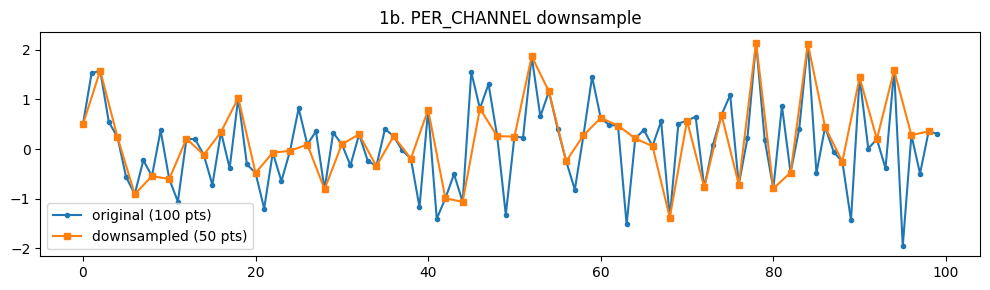

In [5]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(np.arange(100), ts.data[0, :, 0], 'o-', markersize=3, label="original (100 pts)")
ax.plot(np.arange(50) * 2, ts_ds.data[0, :, 0], 's-', markersize=4, label="downsampled (50 pts)")
ax.set_title("1b. PER_CHANNEL downsample")
ax.legend()
plt.tight_layout()
plt.show()

### 1c. PER_CHANNEL on 4D (B, W, T, C)

In [6]:
data_4d = np.random.randn(4, 5, 64, 3)
ts_4d = TimeTensor(data_4d, dims=(Dim.BATCH, Dim.WINDOW, Dim.TIME, Dim.CHANNEL),
                   channels=["ch0", "ch1", "ch2"])

conv_smooth = FunctionTransform(
    fn=lambda x: np.convolve(x, np.ones(5)/5, mode='same'),
    scope=Scope.PER_CHANNEL,
)
ts_4d_out = conv_smooth.fit_transform(ts_4d)

print(f"Shape preserved: {ts_4d.shape} -> {ts_4d_out.shape}")
assert ts_4d.shape == ts_4d_out.shape

Shape preserved: (4, 5, 64, 3) -> (4, 5, 64, 3)


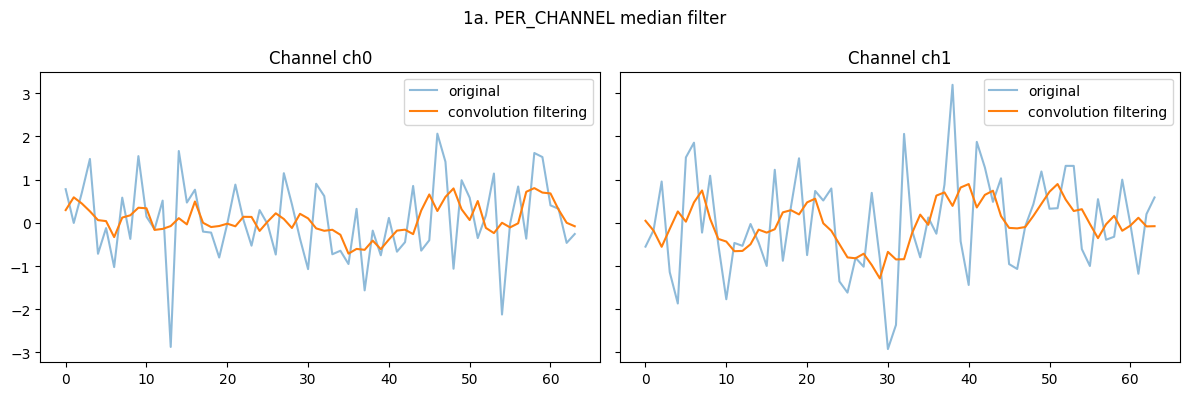

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for i, ch in enumerate([0, 1]):
    axes[i].plot(ts_4d.data[0, 0, :, ch], alpha=0.5, label="original")
    axes[i].plot(ts_4d_out.data[0, 0, :, ch], label="convolution filtering")
    axes[i].set_title(f"Channel {ts_4d.channels.names[ch]}")
    axes[i].legend()
plt.suptitle("1a. PER_CHANNEL median filter")
plt.tight_layout()
plt.show()

### 1d. fn_kwargs forwarding (FFT band-limiting)

In [8]:
def bandlimit(x, cutoff=10):
    """Zero out FFT coefficients above `cutoff`."""
    X = np.fft.rfft(x)
    X[cutoff:] = 0
    return np.fft.irfft(X, n=len(x))

bl = FunctionTransform(fn=bandlimit, scope=Scope.PER_CHANNEL,
                       fn_kwargs={"cutoff": 8})
ts_bl = bl.fit_transform(ts)

print(f"Shape: {ts_bl.shape}")

Shape: (5, 100, 3)


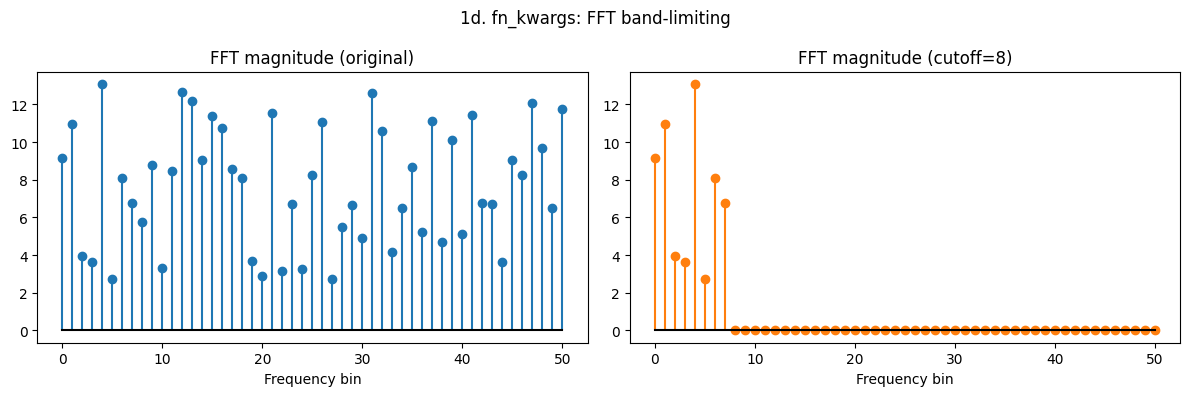

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ch = 0
orig_fft = np.abs(np.fft.rfft(ts.data[0, :, ch]))
bl_fft = np.abs(np.fft.rfft(ts_bl.data[0, :, ch]))

axes[0].stem(orig_fft, linefmt='C0-', markerfmt='C0o', basefmt='k-', label="original")
axes[0].set_title("FFT magnitude (original)")
axes[1].stem(bl_fft, linefmt='C1-', markerfmt='C1o', basefmt='k-', label="band-limited")
axes[1].set_title("FFT magnitude (cutoff=8)")
for ax in axes:
    ax.set_xlabel("Frequency bin")
plt.suptitle("1d. fn_kwargs: FFT band-limiting")
plt.tight_layout()
plt.show()

### 1e. PER_CHANNEL ragged

In [10]:
ragged_samples = [
    np.random.randn(80, 2),
    np.random.randn(120, 2),
    np.random.randn(60, 2),
]
labels = np.array([0, 1, 0])
ts_rag = TimeTensor.from_ragged(ragged_samples, channels=["s1", "s2"], y=labels)

smooth_rag = FunctionTransform(fn=medfilt, scope=Scope.PER_CHANNEL,
                               fn_kwargs={"kernel_size": 5})
ts_rag_out = smooth_rag.fit_transform(ts_rag)

print(f"Ragged preserved: {ts_rag_out.is_ragged}")
for i, s in enumerate(ts_rag_out.samples):
    orig = ragged_samples[i]
    print(f"  Sample {i}: {orig.shape} -> {s.shape}")

print(f"y preserved: {ts_rag_out.y}")

Ragged preserved: True
  Sample 0: (80, 2) -> (80, 2)
  Sample 1: (120, 2) -> (120, 2)
  Sample 2: (60, 2) -> (60, 2)
y preserved: [0 1 0]


---
## 2. FunctionTransform -- PER_SAMPLE

### 2a. Per-sample z-score (dense)

In [11]:
def zscore(x):
    return (x - x.mean(axis=0)) / (x.std(axis=0) + 1e-8)

data_ps = np.random.randn(5, 100, 3) * np.array([10, 1, 0.1]) + np.array([5, -3, 0])
ts_ps = TimeTensor(data_ps, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL),
                   channels=["ch0", "ch1", "ch2"])

zs = FunctionTransform(fn=zscore, scope=Scope.PER_SAMPLE)
ts_zs = zs.fit_transform(ts_ps)

for i in range(ts_zs.data.shape[0]):
    sample_mean = ts_zs.data[i].mean(axis=0)
    print(f"  Sample {i} per-channel mean: {np.round(sample_mean, 6)}")

  Sample 0 per-channel mean: [0. 0. 0.]
  Sample 1 per-channel mean: [ 0. -0. -0.]
  Sample 2 per-channel mean: [-0.  0.  0.]
  Sample 3 per-channel mean: [-0. -0. -0.]
  Sample 4 per-channel mean: [-0. -0. -0.]


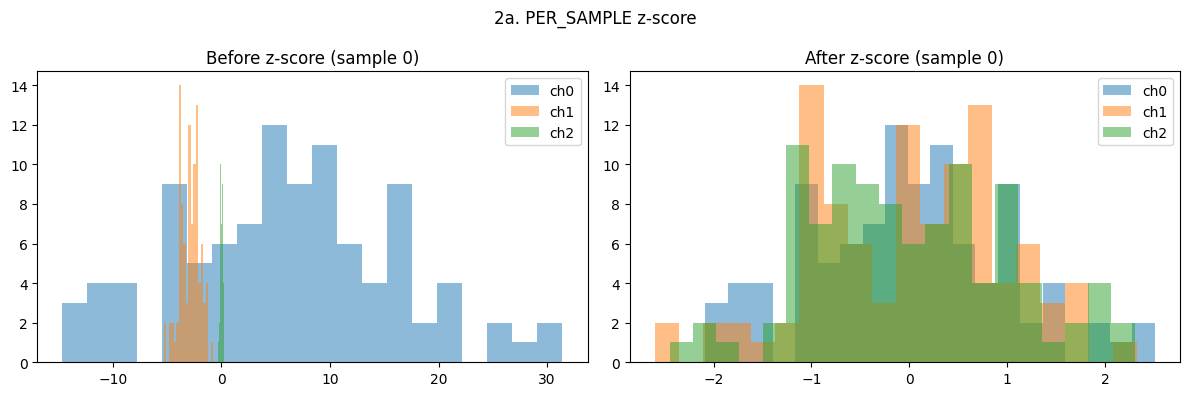

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ch in range(3):
    axes[0].hist(ts_ps.data[0, :, ch], bins=20, alpha=0.5, label=f"ch{ch}")
    axes[1].hist(ts_zs.data[0, :, ch], bins=20, alpha=0.5, label=f"ch{ch}")
axes[0].set_title("Before z-score (sample 0)")
axes[1].set_title("After z-score (sample 0)")
for ax in axes:
    ax.legend()
plt.suptitle("2a. PER_SAMPLE z-score")
plt.tight_layout()
plt.show()

### 2b. Per-sample adaptive clip

In [13]:
data_clip = np.random.randn(5, 200, 2)
# Inject outliers
data_clip[0, 10, 0] = 50.0
data_clip[2, 150, 1] = -40.0
ts_clip = TimeTensor(data_clip, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL))

def adaptive_clip(x):
    lo, hi = np.percentile(x, [1, 99])
    return np.clip(x, lo, hi)

clip_tfm = FunctionTransform(fn=adaptive_clip, scope=Scope.PER_SAMPLE)
ts_clipped = clip_tfm.fit_transform(ts_clip)

print(f"Max before: {ts_clip.data.max():.2f}, after: {ts_clipped.data.max():.2f}")
print(f"Min before: {ts_clip.data.min():.2f}, after: {ts_clipped.data.min():.2f}")

Max before: 50.00, after: 2.60
Min before: -40.00, after: -2.45


In [16]:
ts_clip.data.ravel().shape

(2000,)

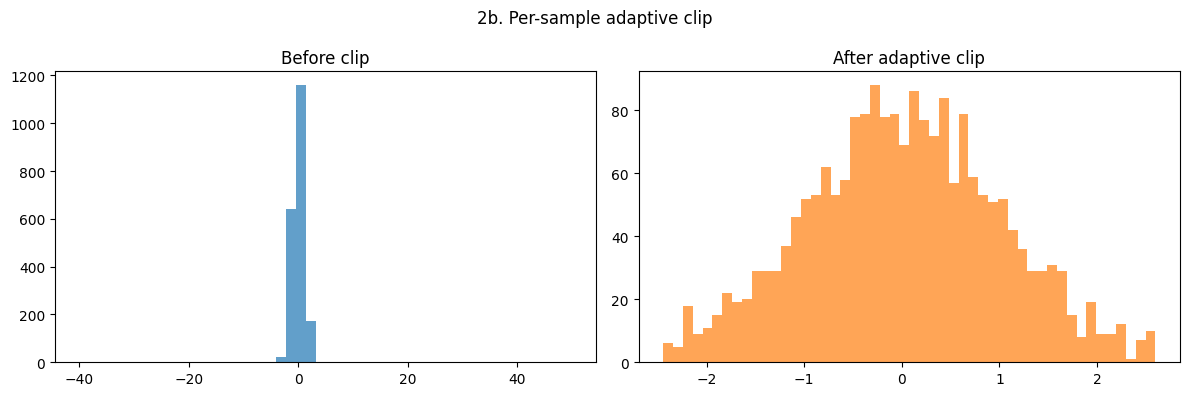

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(ts_clip.data.ravel(), bins=50, color='C0', alpha=0.7)
axes[0].set_title("Before clip")
axes[1].hist(ts_clipped.data.ravel(), bins=50, color='C1', alpha=0.7)
axes[1].set_title("After adaptive clip")
plt.suptitle("2b. Per-sample adaptive clip")
plt.tight_layout()
plt.show()

### 2c. Time trim

In [17]:
data_trim = np.random.randn(5, 100, 3)
ts_trim = TimeTensor(data_trim, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL))

trim_tfm = FunctionTransform(fn=lambda x: x[:-10], scope=Scope.PER_SAMPLE)
ts_trimmed = trim_tfm.fit_transform(ts_trim)

print(f"Shape: {ts_trim.shape} -> {ts_trimmed.shape}")
print(f"Dims preserved: {ts_trimmed.dims}")

Shape: (5, 100, 3) -> (5, 90, 3)
Dims preserved: (Dim.BATCH, Dim.TIME, Dim.CHANNEL)


### 2d. PER_SAMPLE ragged (same shape output -> dense)

In [19]:
# All samples have different lengths but the function pads/truncates to same
ragged_ps = [
    np.random.randn(80, 2),
    np.random.randn(120, 2),
    np.random.randn(100, 2),
]
ts_rag_ps = TimeTensor.from_ragged(ragged_ps, channels=["a", "b"])

def pad_to_100(x):
    """Pad or truncate to exactly 100 timesteps."""
    out = np.zeros((100, x.shape[-1]))
    n = min(x.shape[0], 100)
    out[:n] = x[:n]
    return out

pad_tfm = FunctionTransform(fn=pad_to_100, scope=Scope.PER_SAMPLE)
ts_rag_dense = pad_tfm.fit_transform(ts_rag_ps)

print(f"Input ragged: {ts_rag_ps.is_ragged}")
print(f"Output ragged: {ts_rag_dense.is_ragged}")
print(f"Output shape: {ts_rag_dense.shape}  (ragged -> dense transition)")

Input ragged: True
Output ragged: False
Output shape: (3, 100, 2)  (ragged -> dense transition)


### 2e. PER_SAMPLE ragged (variable shape output -> stays ragged)

In [20]:
ds_sample = FunctionTransform(fn=lambda x: x[::2], scope=Scope.PER_SAMPLE)
ts_rag_var = ds_sample.fit_transform(ts_rag_ps)

print(f"Output ragged: {ts_rag_var.is_ragged}")
for i, s in enumerate(ts_rag_var.samples):
    print(f"  Sample {i}: input {ragged_ps[i].shape} -> output {s.shape}")

Output ragged: True
  Sample 0: input (80, 2) -> output (40, 2)
  Sample 1: input (120, 2) -> output (60, 2)
  Sample 2: input (100, 2) -> output (50, 2)


---
## 3. FunctionTransform -- GLOBAL

### 3a. Element-wise clipping

In [21]:
data_g = np.random.randn(4, 128, 2) * 3
ts_g = TimeTensor(data_g, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL))

clip_global = FunctionTransform(fn=lambda x: np.clip(x, -2, 2), scope=Scope.GLOBAL)
ts_gc = clip_global.fit_transform(ts_g)

print(f"Min/max before: [{ts_g.data.min():.2f}, {ts_g.data.max():.2f}]")
print(f"Min/max after:  [{ts_gc.data.min():.2f}, {ts_gc.data.max():.2f}]")

Min/max before: [-9.25, 10.29]
Min/max after:  [-2.00, 2.00]


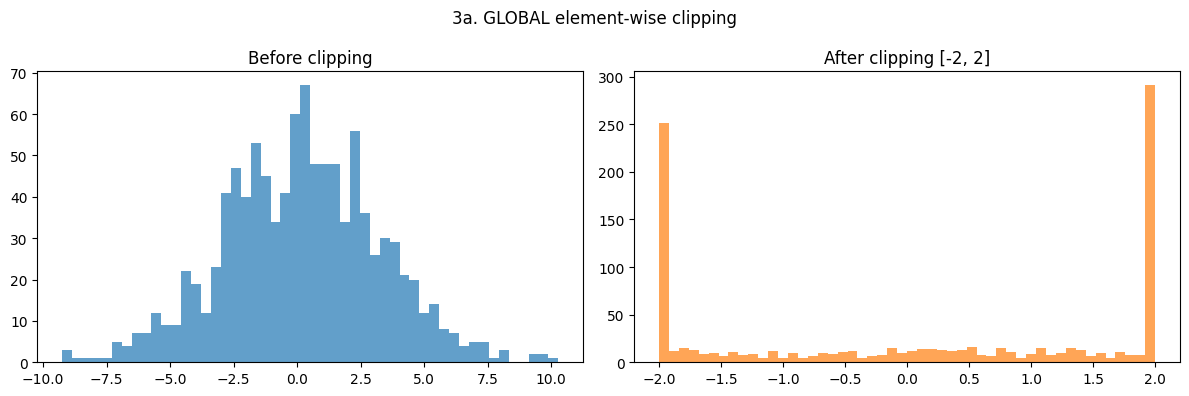

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(ts_g.data.ravel(), bins=50, color='C0', alpha=0.7)
axes[0].set_title("Before clipping")
axes[1].hist(ts_gc.data.ravel(), bins=50, color='C1', alpha=0.7)
axes[1].set_title("After clipping [-2, 2]")
plt.suptitle("3a. GLOBAL element-wise clipping")
plt.tight_layout()
plt.show()

### 3b. Batch FFT (power spectrum)

In [ ]:
data_fft = np.random.randn(4, 128, 2)
ts_fft = TimeTensor(data_fft, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL))

# NOTE:
# Using FunctionTransformer for feature extraction is technically possible,
# but not recommended when the transformation alters the semantic meaning
# of a dimension.
#
# For example, transforming a time-domain signal into a frequency-domain
# representation changes the interpretation of axis 1 from "time" to
# "frequency". FunctionTransformer does not provide a mechanism to
# explicitly update or propagate this semantic change within the data
# structure. As a result, users must manually modify the corresponding
# dimension metadata (e.g., replacing Dim.Time with Dim.Frequency), which
# is error-prone and unintuitive.
#
# For transformations that change the meaning or identity of a dimension,
# the preferred approach is to use a FeatureExtractor transformer. This
# abstraction is designed to explicitly define which input dimension is
# consumed and what it is replaced with, ensuring consistency, clarity,
# and safer downstream processing.
#
# In summary:
# - Use FunctionTransformer for value-preserving or semantics-preserving operations.
# - Use FeatureExtractor for any transformation that changes dimensional meaning.

power_spec = FunctionTransform(
    fn=lambda x: np.abs(np.fft.rfft(x, axis=1)) ** 2,
    scope=Scope.GLOBAL,
)
ts_pow = power_spec.fit_transform(ts_fft)

print(f"Shape: {ts_fft.shape} -> {ts_pow.shape}")
print(f"Expected time axis: 128 -> {128 // 2 + 1} = 65")

Shape: (4, 128, 2) -> (4, 65, 2)
Expected time axis: 128 -> 65 = 65


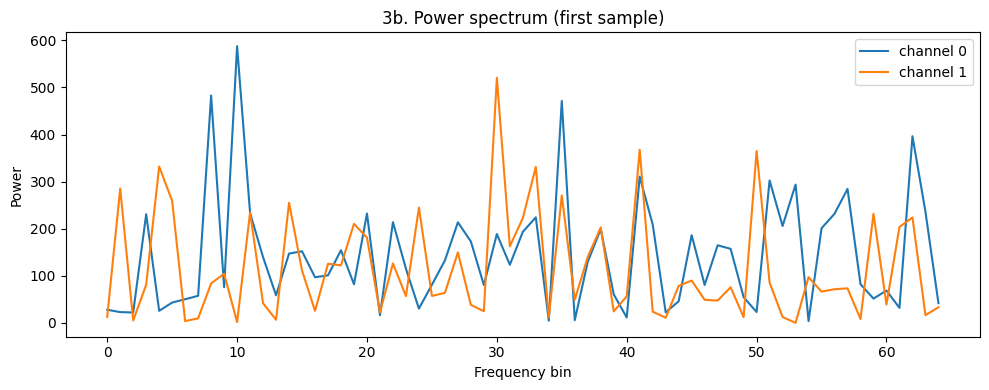

In [25]:
fig, ax = plt.subplots(figsize=(10, 4))
for ch in range(2):
    ax.plot(ts_pow.data[0, :, ch], label=f"channel {ch}")
ax.set_xlabel("Frequency bin")
ax.set_ylabel("Power")
ax.set_title("3b. Power spectrum (first sample)")
ax.legend()
plt.tight_layout()
plt.show()

---
## 4. StatefulFunctionTransform

### 4a. GLOBAL scaler (fit learns mean/std, transform applies)

In [31]:
data_st = np.random.randn(8, 200, 3) * np.array([10, 1, 0.5]) + np.array([5, -2, 0])
ts_st = TimeTensor(data_st, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL),
                   channels=["ch0", "ch1", "ch2"])

scaler = StatefulFunctionTransform(
    fit_fn=lambda x: {
        "mu": x.mean(axis=(0, 1), keepdims=True),
        "sigma": x.std(axis=(0, 1), keepdims=True),
    },
    transform_fn=lambda x, s: (x - s["mu"]) / (s["sigma"] + 1e-8),
    scope=Scope.GLOBAL,
)
ts_scaled = scaler.fit_transform(ts_st)

print(f"Learned state mu:    {scaler._state['mu'].ravel()}")
print(f"Learned state sigma: {scaler._state['sigma'].ravel()}")
print(f"Per-channel mean after: {ts_scaled.data.mean(axis=(0,1)).round(4)}")

Learned state mu:    [ 5.15103998 -1.99666321  0.0173477 ]
Learned state sigma: [9.8396588  1.02017698 0.4999625 ]
Per-channel mean after: [ 0.  0. -0.]


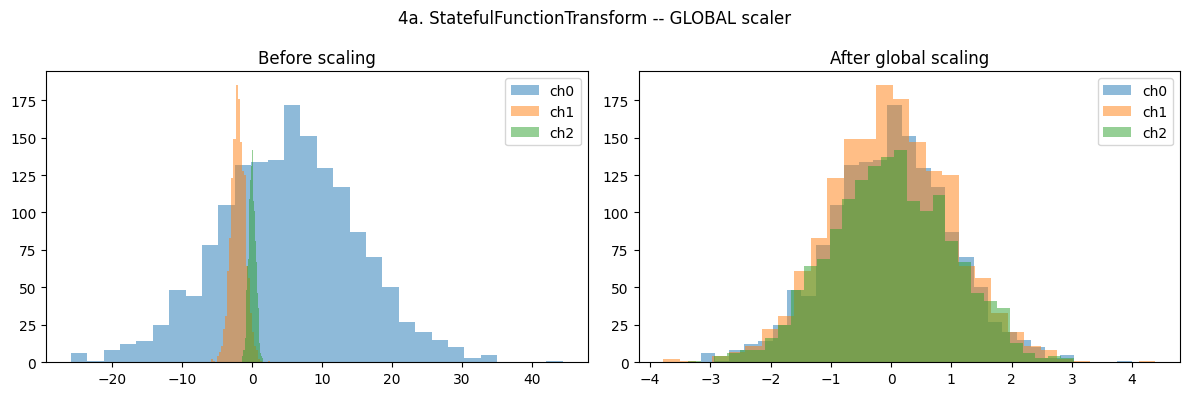

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ch in range(3):
    axes[0].hist(ts_st.data[:, :, ch].ravel(), bins=30, alpha=0.5, label=f"ch{ch}")
    axes[1].hist(ts_scaled.data[:, :, ch].ravel(), bins=30, alpha=0.5, label=f"ch{ch}")
axes[0].set_title("Before scaling")
axes[1].set_title("After global scaling")
for ax in axes:
    ax.legend()
plt.suptitle("4a. StatefulFunctionTransform -- GLOBAL scaler")
plt.tight_layout()
plt.show()

### 4b. PER_CHANNEL adaptive percentile clipping

In [35]:
data_pc = np.random.randn(6, 150, 3)
# Inject outliers in different channels
data_pc[0, 10, 0] = 50.0
data_pc[1, 20, 1] = -60.0
data_pc[2, 30, 2] = 40.0
ts_pc = TimeTensor(data_pc, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL),
                   channels=["x", "y", "z"])

clip_stateful = StatefulFunctionTransform(
    fit_fn=lambda x: {"lo": np.percentile(x, 1), "hi": np.percentile(x, 99)},
    transform_fn=lambda x, s: np.clip(x, s["lo"], s["hi"]),
    scope=Scope.PER_CHANNEL,
)
ts_pc_out = clip_stateful.fit_transform(ts_pc)

print("Learned clip bounds per channel:")
for i, state in enumerate(clip_stateful._channel_states):
    print(f"  ch{i}: [{state['lo']:.3f}, {state['hi']:.3f}]")

Learned clip bounds per channel:
  ch0: [-2.244, 2.336]
  ch1: [-2.532, 2.029]
  ch2: [-2.352, 2.339]


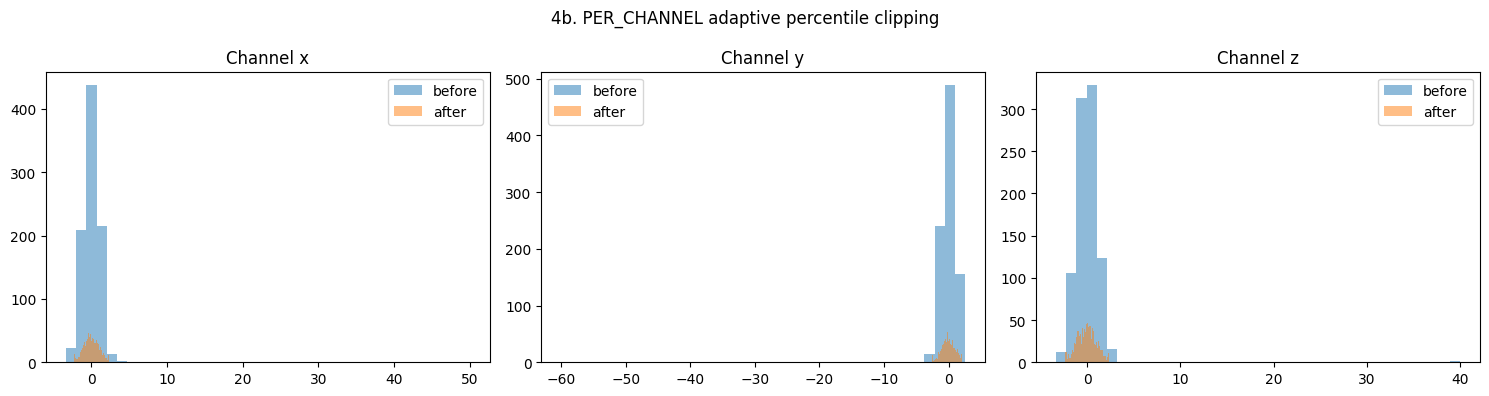

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ch in range(3):
    axes[ch].hist(ts_pc.data[:, :, ch].ravel(), bins=40, alpha=0.5, label="before")
    axes[ch].hist(ts_pc_out.data[:, :, ch].ravel(), bins=40, alpha=0.5, label="after")
    axes[ch].set_title(f"Channel {ts_pc.channels.names[ch]}")
    axes[ch].legend()
plt.suptitle("4b. PER_CHANNEL adaptive percentile clipping")
plt.tight_layout()
plt.show()

### 4c. PER_CHANNEL ragged

In [37]:
rag_samples = [
    np.random.randn(80, 2) * 5 + 10,
    np.random.randn(120, 2) * 5 + 10,
    np.random.randn(60, 2) * 5 + 10,
]
ts_rag_st = TimeTensor.from_ragged(rag_samples, channels=["a", "b"])

centering = StatefulFunctionTransform(
    fit_fn=lambda x: {"mu": x.mean()},
    transform_fn=lambda x, s: x - s["mu"],
    scope=Scope.PER_CHANNEL,
)
ts_rag_centered = centering.fit_transform(ts_rag_st)

# State is learned from concatenated samples
print("Channel means before:")
for ch in range(2):
    vals = np.concatenate([s[:, ch] for s in rag_samples])
    print(f"  ch{ch}: {vals.mean():.4f}")

print("Channel means after:")
for ch in range(2):
    vals = np.concatenate([s[:, ch] for s in ts_rag_centered.samples])
    print(f"  ch{ch}: {vals.mean():.4f}")

Channel means before:
  ch0: 10.1658
  ch1: 9.9866
Channel means after:
  ch0: 0.0000
  ch1: 0.0000


### 4d. fit_scope vs transform_scope (cross-scope)

In [38]:
# fit_scope=PER_SAMPLE, scope=GLOBAL -- valid combination
# The fit learns state from per-sample view, but transform applies globally.
cross_scope = StatefulFunctionTransform(
    fit_fn=lambda x: {"scale": x.std()},
    transform_fn=lambda x, s: x / (s["scale"] + 1e-8),
    scope=Scope.GLOBAL,
    fit_scope=Scope.PER_SAMPLE,
)

data_cs = np.random.randn(4, 50, 2) * 5
ts_cs = TimeTensor(data_cs, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL))
ts_cs_out = cross_scope.fit_transform(ts_cs)

print(f"fit_scope=PER_SAMPLE, scope=GLOBAL")
print(f"Learned state: scale={cross_scope._state['scale']:.4f}")
print(f"Shape preserved: {ts_cs.shape} -> {ts_cs_out.shape}")
print()
print("Note: GLOBAL fit + PER_CHANNEL transform is invalid because")
print("GLOBAL fit produces a single state dict, but PER_CHANNEL transform")
print("expects a list of per-channel states (_channel_states).")

fit_scope=PER_SAMPLE, scope=GLOBAL
Learned state: scale=5.1571
Shape preserved: (4, 50, 2) -> (4, 50, 2)

Note: GLOBAL fit + PER_CHANNEL transform is invalid because
GLOBAL fit produces a single state dict, but PER_CHANNEL transform
expects a list of per-channel states (_channel_states).


### 4e. No data leakage: fit on train, transform test

In [39]:
np.random.seed(42)
data_leak = np.random.randn(20, 100, 2) * np.array([5, 2]) + np.array([3, -1])
ts_leak = TimeTensor(data_leak, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL),
                     channels=["s0", "s1"])

train, test = temporal_split(ts_leak, test_ratio=0.2)

scaler2 = StatefulFunctionTransform(
    fit_fn=lambda x: {
        "mu": x.mean(axis=(0, 1), keepdims=True),
        "sigma": x.std(axis=(0, 1), keepdims=True),
    },
    transform_fn=lambda x, s: (x - s["mu"]) / (s["sigma"] + 1e-8),
    scope=Scope.GLOBAL,
)
scaler2.fit(train)
Xt_train = scaler2.transform(train)
Xt_test = scaler2.transform(test)   # uses train statistics

print(f"Train shape: {train.shape}, Test shape: {test.shape}")
print(f"Train mean (should be ~0): {Xt_train.data.mean(axis=(0,1)).round(4)}")
print(f"Test mean (slightly off -- expected): {Xt_test.data.mean(axis=(0,1)).round(4)}")

Train shape: (16, 100, 2), Test shape: (4, 100, 2)
Train mean (should be ~0): [-0. -0.]
Test mean (slightly off -- expected): [ 0.0505 -0.0687]


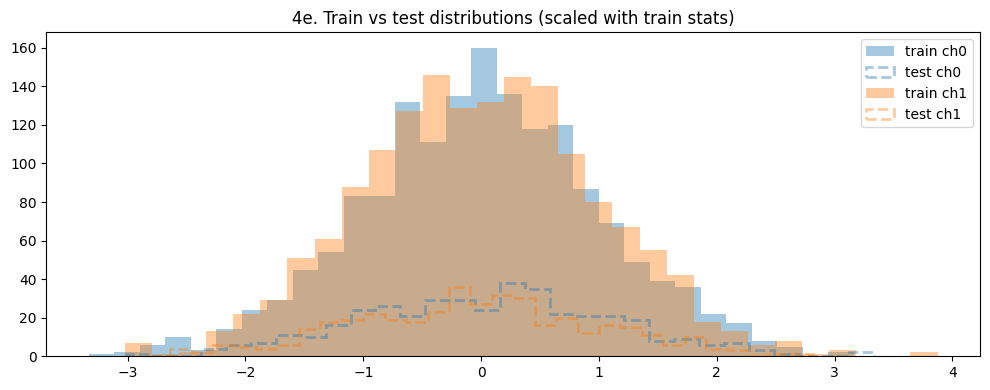

In [40]:
fig, ax = plt.subplots(figsize=(10, 4))
for ch in range(2):
    ax.hist(Xt_train.data[:, :, ch].ravel(), bins=30, alpha=0.4,
            label=f"train ch{ch}", color=f"C{ch}")
    ax.hist(Xt_test.data[:, :, ch].ravel(), bins=30, alpha=0.4,
            label=f"test ch{ch}", color=f"C{ch}", linestyle='--', histtype='step', linewidth=2)
ax.set_title("4e. Train vs test distributions (scaled with train stats)")
ax.legend()
plt.tight_layout()
plt.show()

---
## 5. Integration Tests

### 5a. FunctionTransform in Pipeline (step-by-step)

In [41]:
np.random.seed(0)
X_data = np.random.randn(8, 200, 3)
X = TimeTensor(X_data, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL),
               channels=["a", "b", "c"])

# Step 1: FunctionTransform (medfilt)
X1 = FunctionTransform(fn=medfilt, scope=Scope.PER_CHANNEL,
                       fn_kwargs={"kernel_size": 5}).fit_transform(X)
print(f"After smooth: {X1.shape}")

# Step 2: StandardScaler
X2 = StandardScaler().fit_transform(X1)
print(f"After scale: {X2.shape}, mean={X2.data.mean():.4f}")

# Step 3: SlidingWindow
X3 = SlidingWindow(size=50, stride=25).fit_transform(X2)
print(f"After window: {X3.shape}, dims={X3.dims}")

# Step 4: make_statistical_extractor
X4 = make_statistical_extractor(["mean", "std"]).fit_transform(X3)
print(f"After stats: {X4.shape}")

# Step 5: Flatten
X5 = Flatten().fit_transform(X4)
print(f"After flatten: {X5.shape}")

After smooth: (8, 200, 3)
After scale: (8, 200, 3), mean=-0.0000
After window: (8, 7, 50, 3), dims=(Dim.BATCH, Dim.WINDOW, Dim.TIME, Dim.CHANNEL)
After stats: (8, 7, 2, 3)
After flatten: (8, 42)


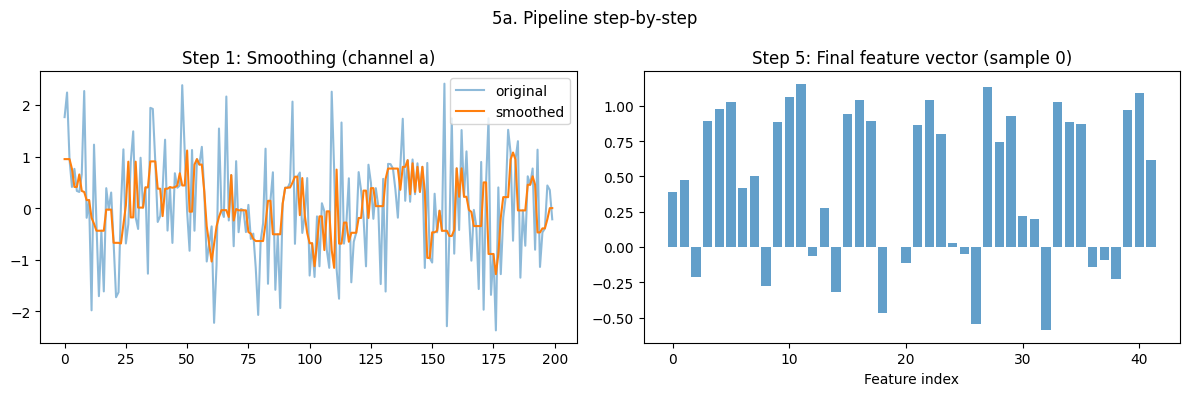

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(X.data[0, :, 0], alpha=0.5, label="original")
axes[0].plot(X1.data[0, :, 0], label="smoothed")
axes[0].set_title("Step 1: Smoothing (channel a)")
axes[0].legend()

axes[1].bar(range(X5.data.shape[1]), X5.data[0], alpha=0.7)
axes[1].set_title("Step 5: Final feature vector (sample 0)")
axes[1].set_xlabel("Feature index")
plt.suptitle("5a. Pipeline step-by-step")
plt.tight_layout()
plt.show()

### 5b. FunctionTransform in ChannelSelect

In [43]:
data_cs2 = np.random.randn(4, 100, 6)
ch_names = ["acc_x", "acc_y", "acc_z", "gyro_x", "gyro_y", "gyro_z"]
ts_cs2 = TimeTensor(data_cs2, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL),
                    channels=ch_names,
                    channel_groups={"acc": "acc_*", "gyro": "gyro_*"})

# Smooth only acc_* channels, gyro_* passthrough
cs_tfm = ChannelSelect(
    channels="acc_*",
    transform=FunctionTransform(fn=medfilt, scope=Scope.PER_CHANNEL,
                                fn_kwargs={"kernel_size": 7}),
)
ts_cs2_out = cs_tfm.fit_transform(ts_cs2)

# Verify gyro channels unchanged
gyro_orig = ts_cs2.data[:, :, 3:]
gyro_names = ["gyro_x", "gyro_y", "gyro_z"]
gyro_idx = [ts_cs2_out.channels.names.index(n) for n in gyro_names]
gyro_out = ts_cs2_out.data[:, :, gyro_idx]
print(f"Gyro channels unchanged: {np.array_equal(gyro_orig, gyro_out)}")

Gyro channels unchanged: True


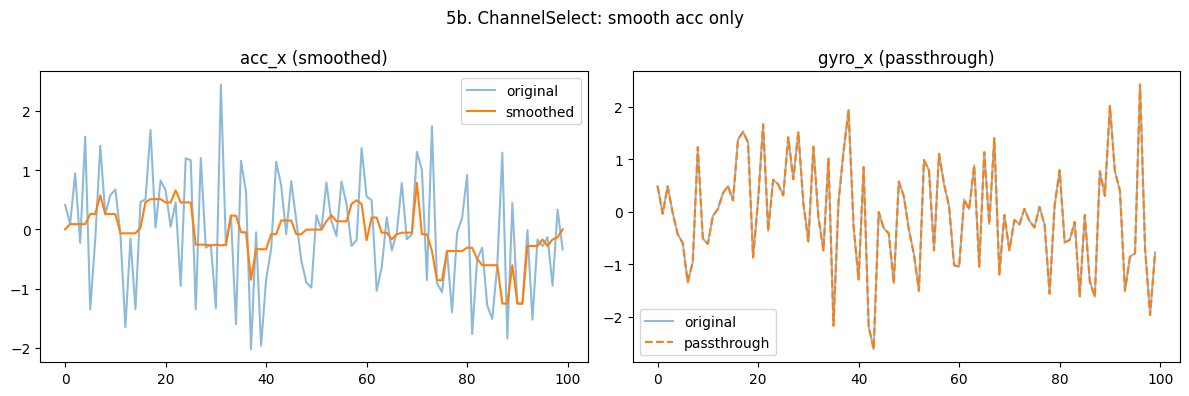

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# acc channel: should be smoothed
acc_idx_out = ts_cs2_out.channels.names.index("acc_x")
axes[0].plot(ts_cs2.data[0, :, 0], alpha=0.5, label="original")
axes[0].plot(ts_cs2_out.data[0, :, acc_idx_out], label="smoothed")
axes[0].set_title("acc_x (smoothed)")
axes[0].legend()

# gyro channel: should be unchanged
gyro_idx_out = ts_cs2_out.channels.names.index("gyro_x")
axes[1].plot(ts_cs2.data[0, :, 3], alpha=0.5, label="original")
axes[1].plot(ts_cs2_out.data[0, :, gyro_idx_out], '--', label="passthrough")
axes[1].set_title("gyro_x (passthrough)")
axes[1].legend()
plt.suptitle("5b. ChannelSelect: smooth acc only")
plt.tight_layout()
plt.show()

### 5c. Mixed stateful + stateless pipeline (step-by-step)

In [48]:
np.random.seed(7)
data_mix = np.random.randn(20, 100, 3) * 10
ts_mix = TimeTensor(data_mix, dims=(Dim.BATCH, Dim.TIME, Dim.CHANNEL),
                    channels=["x", "y", "z"])

train_m, test_m = temporal_split(ts_mix, test_ratio=0.2)

# Step 1: FunctionTransform (clip)
clip_step = FunctionTransform(fn=lambda x: np.clip(x, -20, 20), scope=Scope.GLOBAL)

# Step 2: StatefulFunctionTransform (scale)
scale_step = StatefulFunctionTransform(
    fit_fn=lambda x: {
        "mu": x.mean(axis=(0, 1), keepdims=True),
        "sigma": x.std(axis=(0, 1), keepdims=True),
    },
    transform_fn=lambda x, s: (x - s["mu"]) / (s["sigma"] + 1e-8),
    scope=Scope.GLOBAL,
)

# Step 3: Flatten
flat_step = Flatten()

# Fit on train
X_t1 = clip_step.fit_transform(train_m)
X_t2 = scale_step.fit_transform(X_t1)
X_t3 = flat_step.fit_transform(X_t2)

# Transform test
X_te1 = clip_step.transform(test_m)
X_te2 = scale_step.transform(X_te1)
X_te3 = flat_step.transform(X_te2)

print(f"Train features: {X_t3.shape}")
print(f"Test features:  {X_te3.shape}")
print(f"Feature counts match: {X_t3.shape[1] == X_te3.shape[1]}")

Train features: (16, 300)
Test features:  (4, 300)
Feature counts match: True


### 5d. Repr

In [49]:
# Named function
named_tfm = FunctionTransform(fn=medfilt, scope=Scope.PER_CHANNEL, name="median_filter")
print(repr(named_tfm))

# Unnamed lambda
unnamed_tfm = FunctionTransform(fn=lambda x: x * 2, scope=Scope.GLOBAL)
print(repr(unnamed_tfm))

# StatefulFunctionTransform
stateful_repr = StatefulFunctionTransform(
    fit_fn=lambda x: {}, transform_fn=lambda x, s: x,
    scope=Scope.PER_CHANNEL, name="my_scaler"
)
print(repr(stateful_repr))

FunctionTransform(fn=median_filter, scope=PER_CHANNEL)
FunctionTransform(fn=<lambda>, scope=GLOBAL)
StatefulFunctionTransform(my_scaler, scope=PER_CHANNEL)
